# Guided exercise: frame the call list, split it, score the baseline

You and the trainer build this together, one step at a time, during case 1. Each step has a TODO cell: replace the `None` with your answer and run the cell; the progress cell tells you which steps are done. The answer sits in the last cell. Try every step before you scroll to it.

What you will have at the end: a framed problem in three lines, the 13 input columns, a 0/1 target, the week's split with the seed stated, and the baseline accuracy every later model must beat.

**Search terms:** problem framing, train validation test split, stratify, random_state, DummyClassifier.

In [1]:
# Tools for this notebook, and one helper that prints a check as PASS or FAIL.
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

def check(label, ok):
    print(("PASS  " if ok else "FAIL  ") + label)

import hashlib

def fingerprint(names):
    """A short code for a list of names, so the check can test your list without printing the answer."""
    return hashlib.md5(",".join(sorted(names)).encode()).hexdigest()[:10]

def todo_or(label, ok, value):
    """Print TODO while a step still holds None, then PASS or FAIL once it is filled."""
    if value is None:
        print("TODO  " + label)
    else:
        check(label, ok())

In [2]:
# Load the day's public dataset once; later runs read the cached copy.
CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0), cached after the first download."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"  # verified 28 October 2026
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

bank = load_bank()
print(bank.shape)

(41188, 21)


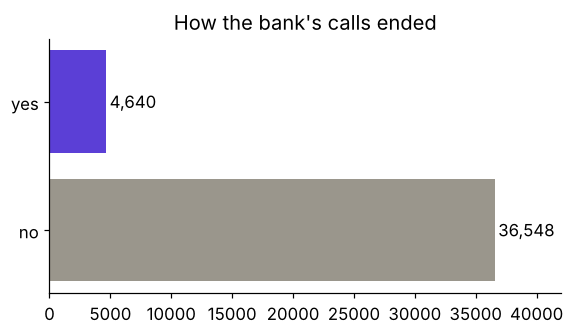

In [3]:
# The picture to frame from: how the 41,188 calls ended.
counts = bank["y"].value_counts()
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(["no", "yes"], [counts["no"], counts["yes"]], color=["#9A968C", "#5B3FD6"])
for i, v in enumerate([counts["no"], counts["yes"]]):
    ax.text(v + 300, i, f"{v:,}", va="center")
ax.set_xlim(0, 42000); ax.set_title("How the bank's calls ended"); plt.show()

## Step 1. Frame it in three lines

Write the input (what the bank knows), the target (what we score against) and the prediction time (the moment the score is made), each as a short phrase.

In [4]:
# TODO: replace each None with a short phrase.
frame = {
    "input": None,            # what the bank knows about the client at the prediction time
    "target": None,           # the column we predict, and when it becomes known
    "prediction_time": None,  # the moment the score is made
}
print(frame)

{'input': None, 'target': None, 'prediction_time': None}


## Step 2. Pick the columns known at the prediction time

From the 20 input columns, list the ones the bank holds on the morning of the call: the client's profile and how this and earlier campaigns went. Today's answer has 13 names. Leave the other seven for Wednesday.

In [5]:
# TODO: a list of 13 column names from bank.columns.
print(list(bank.columns))
KNOWN = None
print(KNOWN)

['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']
None


## Step 3. Turn the target into 0 and 1

In [6]:
# TODO: y should be 1 where bank["y"] is "yes" and 0 otherwise, as integers.
y = None
print(None if y is None else y.value_counts().to_dict())

None


## Step 4. Split with a stated seed

Cut the test slice first, 20 percent, stratified on y, and seal it. Split what is left 75 to 25 into train and validation, stratified again. Use the week's seed, 42.

In [7]:
# TODO: set SEED and build train_idx, val_idx, test_idx with train_test_split.
from sklearn.model_selection import train_test_split
SEED = None
train_idx = val_idx = test_idx = None
print(None if train_idx is None else (len(train_idx), len(val_idx), len(test_idx)))

None


## Step 5. Score the baseline on validation

The baseline says "no" to every client. Its accuracy is the share of no in the validation slice.

In [8]:
# TODO: the baseline's accuracy on the validation rows, as a number between 0 and 1.
baseline = None
print(baseline)

None


In [9]:
# Progress: which steps are done?
todo_or("step 1: all three framing lines written", lambda: all(frame.values()), None if not all(frame.values()) else frame)
todo_or("step 2: the 13 columns known on the morning of the call", lambda: len(KNOWN) == 13 and fingerprint(KNOWN) == "0c9125ea0b", KNOWN)
todo_or("step 3: y has 4,640 ones", lambda: int(y.sum()) == 4640, y)
todo_or("step 4: 24,712 / 8,238 / 8,238 with seed 42", lambda: SEED == 42 and (len(train_idx), len(val_idx), len(test_idx)) == (24712, 8238, 8238), train_idx)
todo_or("step 5: baseline accuracy 0.8874", lambda: round(baseline, 4) == 0.8874, baseline)

TODO  step 1: all three framing lines written
TODO  step 2: the 13 columns known on the morning of the call
TODO  step 3: y has 4,640 ones
TODO  step 4: 24,712 / 8,238 / 8,238 with seed 42
TODO  step 5: baseline accuracy 0.8874


## The answer

Run this only after you have tried every step. It fills each step and runs the same progress checks.

In [10]:
# The answer, step by step.
frame = {"input": "the client's profile and campaign history as of the morning of the call",
         "target": "y, yes or no, known once the call ends",
         "prediction_time": "the morning of the call, before anyone dials"}
KNOWN = ["age", "job", "marital", "education", "default", "housing", "loan",
         "contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
y = (bank["y"] == "yes").astype(int)
SEED = 42
rest_idx, test_idx = train_test_split(bank.index, test_size=0.20, stratify=y, random_state=SEED)
train_idx, val_idx = train_test_split(rest_idx, test_size=0.25, stratify=y.loc[rest_idx], random_state=SEED)
baseline = float((y.loc[val_idx] == 0).mean())
print(f"split {len(train_idx):,} / {len(val_idx):,} / {len(test_idx):,}; baseline accuracy on validation {baseline:.4f}")

todo_or("step 1: all three framing lines written", lambda: all(frame.values()), frame)
todo_or("step 2: the 13 columns known on the morning of the call", lambda: len(KNOWN) == 13 and fingerprint(KNOWN) == "0c9125ea0b", KNOWN)
todo_or("step 3: y has 4,640 ones", lambda: int(y.sum()) == 4640, y)
todo_or("step 4: 24,712 / 8,238 / 8,238 with seed 42", lambda: SEED == 42 and (len(train_idx), len(val_idx), len(test_idx)) == (24712, 8238, 8238), train_idx)
todo_or("step 5: baseline accuracy 0.8874", lambda: round(baseline, 4) == 0.8874, baseline)

split 24,712 / 8,238 / 8,238; baseline accuracy on validation 0.8874
PASS  step 1: all three framing lines written
PASS  step 2: the 13 columns known on the morning of the call
PASS  step 3: y has 4,640 ones
PASS  step 4: 24,712 / 8,238 / 8,238 with seed 42
PASS  step 5: baseline accuracy 0.8874


**What the baseline proves.** Saying no to every client is right 88.74 percent of the time. A model that scores 0.88 has learned the share of no and nothing else; case 2 asks the logistic model to beat 0.8874 and measures by how much.